# SHAP subscriber-retention recreation

Adapted from the SHAP documentation article [Be careful when interpreting predictive models in search of causal insights](https://shap.readthedocs.io/en/latest/example_notebooks/overviews/Be%20careful%20when%20interpreting%20predictive%20models%20in%20search%20of%20causal%20insights.html). The local implementation was introduced in commit [56f109a](https://github.com/tttre/ShapCounterexamples/commit/56f109a065cbc46f77cc55434bdf29a7e39a73e9).

This recreation is separate from the journal implementations in `../src/`. Use the repository environment and run cells from top to bottom; see [README.md](README.md). Existing saved outputs are retained from the earlier run.


In [1]:
import sys
from pathlib import Path

# Locate the project from the repository root or a nested notebook folder.
project_root = None
for directory in (Path.cwd(), *Path.cwd().parents):
    for candidate in (directory, directory / "SHAP Counterexamples"):
        if (candidate / "experiment_recreation").is_dir() and (candidate / "src").is_dir():
            project_root = candidate
            break
    if project_root is not None:
        break
if project_root is None:
    raise RuntimeError("Open this notebook from within the ShapCounterexamples repository.")
sys.path.insert(0, str(project_root))

print("Python:", sys.executable)
print("Working directory:", Path.cwd())

import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.metrics import log_loss

from experiment_recreation.synthesis import generate_retention_dataset
from experiment_recreation.Predictors.retention_xgboost import fit_retention_xgboost

dataset = generate_retention_dataset(n=1_000, seed=0)

print("Dataset shape:", dataset.shape)
dataset.head()

Python: /Users/leoan/Workspace/ETH_Zurich/ShapCounterexamples/.venv/bin/python
Working directory: /Users/leoan/Workspace/ETH_Zurich/ShapCounterexamples/SHAP Counterexamples
Dataset shape: (1000, 9)


,Sales calls,Interactions,Economy,Last upgrade,Discount,Monthly usage,Ad spend,Bugs reported,score
0,2.0,2.0,0.951411,14.580310,0.338258,0.239820,0.218475,1.0,0
1,3.0,3.0,0.910396,5.218480,0.259749,0.470241,0.464395,0.0,0
2,2.0,2.0,0.584663,4.596991,0.274570,0.160262,0.154536,0.0,0
3,2.0,2.0,0.303549,7.953345,0.346479,0.454978,0.420979,0.0,0
4,2.0,2.0,0.329961,15.747296,0.301240,0.731706,0.694451,0.0,0


In [2]:
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.metrics import log_loss

from experiment_recreation.synthesis import generate_retention_dataset
from experiment_recreation.Predictors.retention_xgboost import fit_retention_xgboost


training_data = generate_retention_dataset(n=10_000, seed=0)

X = training_data.drop(columns="score")
y = training_data["score"]

model = fit_retention_xgboost(X, y, seed=0)

print("Training finished.")
print("Boosting rounds:", model.num_boosted_rounds())

Training finished.
Boosting rounds: 5547


In [3]:
test_data = generate_retention_dataset(n=5_000, seed=1)

X_test = test_data.drop(columns="score")
y_test = test_data["score"]

p_test = model.predict(xgb.DMatrix(X_test))

# A simple reference: predict the same renewal probability for everyone.
p_baseline = np.full(len(y_test), y.mean())

model_loss = log_loss(y_test, p_test)
baseline_loss = log_loss(y_test, p_baseline)

print(f"Model test log loss:    {model_loss:.4f}")
print(f"Baseline test log loss: {baseline_loss:.4f}")

Model test log loss:    0.5546
Baseline test log loss: 0.6145


In [4]:
pd.DataFrame({
    "observed_renewal": y_test.iloc[:10].to_numpy(),
    "predicted_probability": p_test[:10],
})

,observed_renewal,predicted_probability
0,0,0.430410
1,0,0.209360
2,1,0.398746
3,0,0.265150
4,0,0.175117
5,0,0.110951
6,0,0.068922
7,0,0.471351
8,0,0.380775
9,1,0.262725


In [5]:
import numpy as np
import xgboost as xgb
import shap

# Keep the feature order used during training.
X_explain = X.loc[:, model.feature_names]

explainer = shap.TreeExplainer(
    model,
    feature_perturbation="tree_path_dependent",
    model_output="raw",
)

shap_values = explainer(X_explain)

print("SHAP version:", shap.__version__)
print("SHAP array shape:", shap_values.values.shape)

/Users/leoan/Workspace/ETH_Zurich/ShapCounterexamples/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP version: 0.54.1
SHAP array shape: (10000, 8)


In [6]:
raw_predictions = model.predict(
    xgb.DMatrix(X_explain),
    output_margin=True,
)

reconstructed = (
    shap_values.base_values
    + shap_values.values.sum(axis=1)
)

max_error = np.max(np.abs(raw_predictions - reconstructed))
print(f"Maximum reconstruction error: {max_error:.6g}")

np.testing.assert_allclose(
    reconstructed,
    raw_predictions,
    rtol=1e-4,
    atol=1e-4,
)

print("Reconstruction check passed.")

Maximum reconstruction error: 1.0252e-05
Reconstruction check passed.


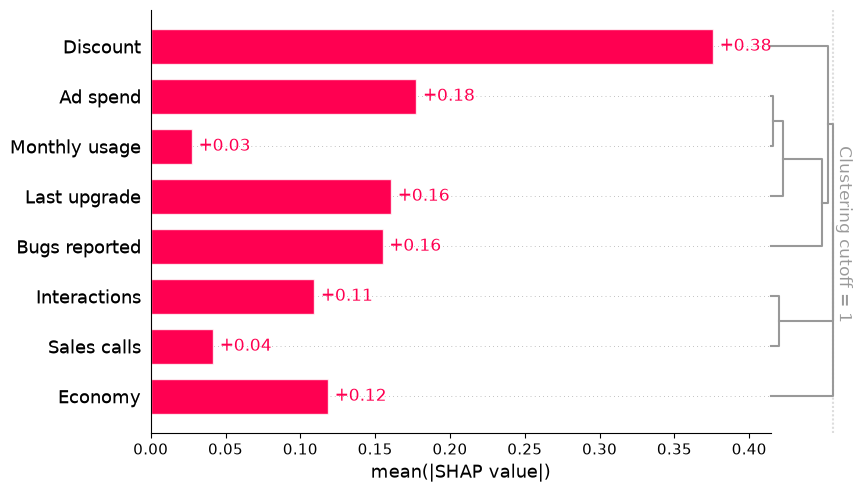

In [7]:
clustering = shap.utils.hclust(
    X_explain,
    y,
    linkage="single",
    random_state=0,
)

shap.plots.bar(
    shap_values,
    max_display=X_explain.shape[1],
    clustering=clustering,
    clustering_cutoff=1,
)

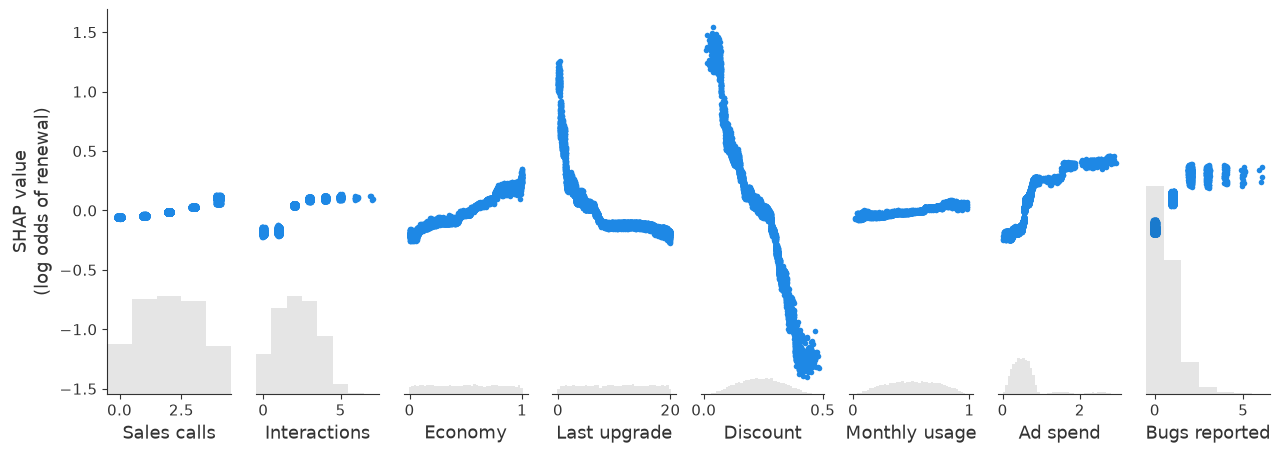

In [8]:
shap.plots.scatter(
    shap_values,
    ylabel="SHAP value\n(log odds of renewal)",
)